# Chest X-ray Pneumonia Detection (CNN)
A simple CNN that looks at a chest X-ray and says if it is **NORMAL** or **PNEUMONIA**.

## 1. Imports

In [ ]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image

## 2. Load the data

In [ ]:
# download the dataset from Kaggle
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
DATA_DIR = Path(path) / "chest_xray" / "chest_xray"

IMG_SIZE = (180, 180)
BATCH_SIZE = 32

# 90% of the train folder for training, 10% for validation
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.1,
    subset="training",
    seed=123
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.1,
    subset="validation",
    seed=123
)

# test data: shuffle=False so the labels stay in the same order as the predictions
test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print(class_names)   # NORMAL = 0, PNEUMONIA = 1

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Found 5216 files belonging to 2 classes.
Using 4695 files for training.
Found 5216 files belonging to 2 classes.
Using 521 files for validation.
Found 624 files belonging to 2 classes.
['NORMAL', 'PNEUMONIA']


## 3. Build the model

In [ ]:
# random changes to the training images so the model does not just memorize them
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,
    layers.Rescaling(1./255),      # pixels from 0-255 to 0-1

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dropout(0.5),           # helps against overfitting
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")   # 0 = normal, 1 = pneumonia
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Class weights


In [ ]:
num_normal = len(os.listdir(DATA_DIR / "train" / "NORMAL"))
num_pneumonia = len(os.listdir(DATA_DIR / "train" / "PNEUMONIA"))
total = num_normal + num_pneumonia

class_weight = {
    0: total / (2 * num_normal),
    1: total / (2 * num_pneumonia)
}
print(num_normal, num_pneumonia)
print(class_weight)

1342 3876
{0: 1.9441132637853948, 1: 0.6731166150670794}


## 5. Train

In [ ]:
# stop early if the validation loss stops getting better
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=[early_stop],
    class_weight=class_weight
)

Epoch 1/12
147/147 ━━━━━━━━━━━━━━━━━━━━ 48s 274ms/step - accuracy: 0.5838 - loss: 0.6134 - val_accuracy: 0.6200 - val_loss: 0.8011
Epoch 2/12
147/147 ━━━━━━━━━━━━━━━━━━━━ 30s 204ms/step - accuracy: 0.8362 - loss: 0.3523 - val_accuracy: 0.9213 - val_loss: 0.2000
Epoch 3/12
147/147 ━━━━━━━━━━━━━━━━━━━━ 43s 220ms/step - accuracy: 0.8826 - loss: 0.2799 - val_accuracy: 0.8848 - val_loss: 0.2994
Epoch 4/12
147/147 ━━━━━━━━━━━━━━━━━━━━ 32s 219ms/step - accuracy: 0.8916 - loss: 0.2648 - val_accuracy: 0.9386 - val_loss: 0.1352
Epoch 5/12
147/147 ━━━━━━━━━━━━━━━━━━━━ 30s 202ms/step - accuracy: 0.9048 - loss: 0.2310 - val_accuracy: 0.9501 - val_loss: 0.1221
Epoch 6/12
147/147 ━━━━━━━━━━━━━━━━━━━━ 29s 200ms/step - accuracy: 0.9178 - loss: 0.2070 - val_accuracy: 0.9405 - val_loss: 0.1388
Epoch 7/12
147/147 ━━━━━━━━━━━━━━━━━━━━ 41s 197ms/step - accuracy: 0.9278 - loss: 0.1869 - val_accuracy: 0.9347 - val_loss: 0.1308
Epoch 8/12
147/147 ━━━━━━━━━━━━━━━━━━━━ 29s 200ms/step - accuracy: 0.9255 - loss: 0

## 6. Training curves

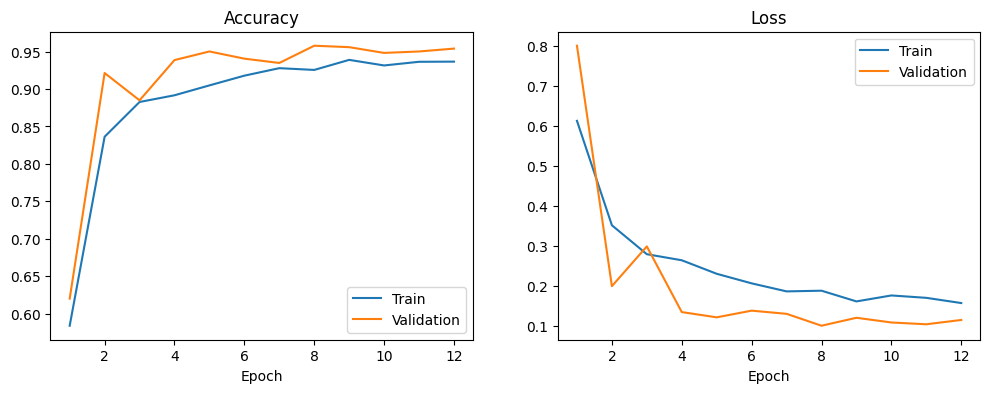

In [ ]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, label="Train")
plt.plot(epochs, val_acc, label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label="Train")
plt.plot(epochs, val_loss, label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

## 7. Test the model

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 189ms/step - accuracy: 0.8462 - loss: 0.3931
Test accuracy: 0.8462
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 145ms/step
              precision    recall  f1-score   support

      NORMAL       0.95      0.62      0.75       234
   PNEUMONIA       0.81      0.98      0.89       390

    accuracy                           0.85       624
   macro avg       0.88      0.80      0.82       624
weighted avg       0.86      0.85      0.84       624



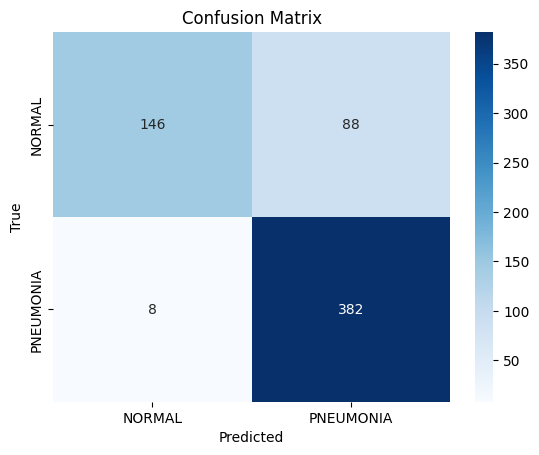

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test accuracy:", round(test_acc, 4))

# predict the whole test set at once
y_pred = (model.predict(test_ds) > 0.5).astype(int).flatten()

# real labels (same order because shuffle=False)
y_true = np.concatenate([labels.numpy() for images, labels in test_ds]).flatten()

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

## 8. Try one image

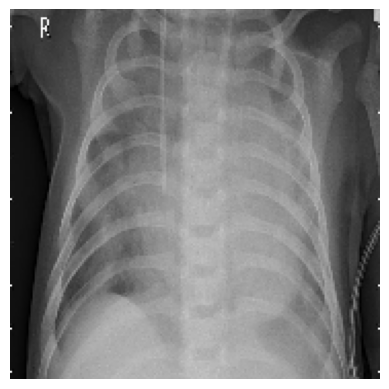

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
Score: 0.9996
Result: Pneumonia


In [ ]:
# take one pneumonia image from the test folder
folder = DATA_DIR / "test" / "PNEUMONIA"
sample_path = folder / sorted(os.listdir(folder))[4]

img = image.load_img(sample_path, target_size=IMG_SIZE)
plt.imshow(img)
plt.axis("off")
plt.show()

x = np.expand_dims(image.img_to_array(img), axis=0)
score = model.predict(x)[0][0]

print("Score:", round(float(score), 4))
print("Result:", "Pneumonia" if score > 0.5 else "Normal")